In [78]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


# House Prices - Advanced Regression Techniques

## Tiền xử lý dữ liệu và đánh giá Feature Selection

**Mục tiêu:** Dự đoán giá nhà `SalePrice` và đánh giá hiệu suất của các kỹ thuật Feature Selection với các mô hình cơ bản:

+ SVM (SVR)
+ Random Forest
+ XGBoost

**Thước đo:** RMSE trên `log(SalePrice)`.

## 1. Định nghĩa vấn đề

### Mô tả

Bộ dữ liệu House Prices chứa thông tin về nhiều đặc điểm của một căn nhà và giá bán của căn nhà đó.

### Dữ liệu vào

Các thuộc tính mô tả căn nhà, gồm:

+ Diện tích
+ Chất lượng nhà
+ Số phòng
+ Khu vực
+ Garage
+ Basement
+ Và nhiều thuộc tính khác.

### Kết quả

`SalePrice`: giá bán của căn nhà.

## 2. Chuẩn bị vấn đề

### Khai báo thư viện

In [79]:
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

%matplotlib inline
warnings.filterwarnings("ignore")

### Tham số chương trình

In [80]:
seed = 42

exps_dir = "./exps_house_prices"
os.makedirs(exps_dir, exist_ok=True)

save_dir = f"{exps_dir}/feature_selection"
os.makedirs(save_dir, exist_ok=True)

print("save_dir:", os.path.abspath(save_dir))

save_dir: /kaggle/working/exps_house_prices/feature_selection


### Nạp dữ liệu

In [81]:
data_path = "/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv"

df_org = pd.read_csv(data_path)

print("Shape:", df_org.shape)
display.display(df_org.head())
display.display(df_org.tail())

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


## 3. Khảo sát dữ liệu ban đầu

In [82]:
print("Kích thước dữ liệu:", df_org.shape)
print("\nThông tin dữ liệu:")
df_org.info()

Kích thước dữ liệu: (1460, 81)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  O

In [83]:
print("Số lượng giá trị thiếu theo cột:")
missing = df_org.isnull().sum().sort_values(ascending=False)
display.display(missing[missing > 0].head(30))

Số lượng giá trị thiếu theo cột:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [84]:
print("Thống kê biến số:")
display.display(df_org.describe().T)

Thống kê biến số:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


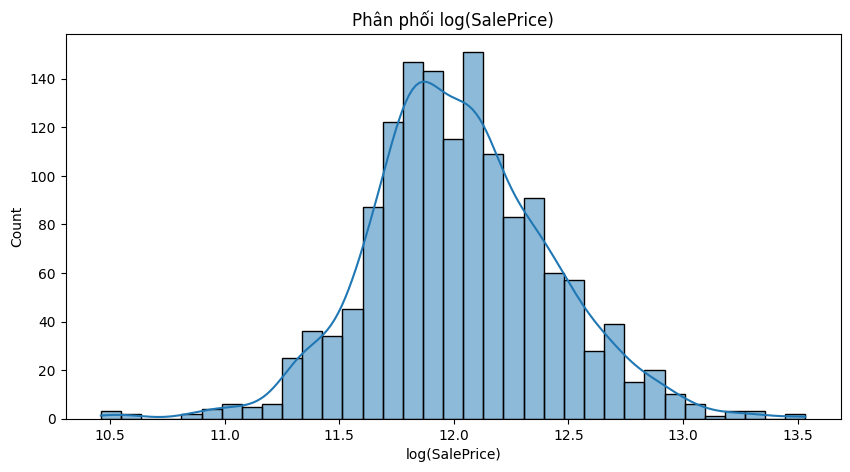

In [85]:
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df_org["SalePrice"]), kde=True)
plt.title("Phân phối log(SalePrice)")
plt.xlabel("log(SalePrice)")
plt.show()

## 4. Chia dữ liệu thực nghiệm

In [86]:
index_all = np.arange(len(df_org))

index_train, index_test = train_test_split(
    index_all,
    test_size=0.20,
    random_state=seed
)

df_train = df_org.iloc[index_train].copy()
df_test = df_org.iloc[index_test].copy()

print(
    f"train: {len(df_train)} / test: {len(df_test)} "
    f"- Tỷ lệ: {len(df_train)/len(df_org):.2f}, "
    f"{len(df_test)/len(df_org):.2f}"
)

train: 1168 / test: 292 - Tỷ lệ: 0.80, 0.20


In [87]:
df_train.to_csv(f"{exps_dir}/train_split.csv", index=False)
df_test.to_csv(f"{exps_dir}/test_split.csv", index=False)

np.savez(
    f"{exps_dir}/idx.npz",
    id_train=index_train,
    id_test=index_test
)

## 5. Tiền xử lý dữ liệu

### Làm sạch dữ liệu

#### Loại bỏ dữ liệu trùng nhau

In [88]:
print("Số dòng trùng trước khi xử lý:", df_train.duplicated().sum())

df_train.drop_duplicates(ignore_index=True, inplace=True)

print("Kích thước sau khi xóa dòng trùng:", df_train.shape)

Số dòng trùng trước khi xử lý: 0
Kích thước sau khi xóa dòng trùng: (1168, 81)


#### Tách Input và Output

In [89]:
X_train_raw = df_train.drop(columns=["SalePrice", "Id"]).copy()
y_train = np.log1p(df_train["SalePrice"].values)

X_test_raw = df_test.drop(columns=["Id"]).copy()
y_test = np.log1p(df_test["SalePrice"].values)

print("X_train:", X_train_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1168, 79)
X_test : (292, 80)
y_train: (1168,)
y_test : (292,)


### Xử lý giá trị rỗng

+ Biến số: thay bằng **median**.
+ Biến danh mục: thay bằng giá trị xuất hiện nhiều nhất.

In [90]:
numeric_columns = X_train_raw.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X_train_raw.select_dtypes(
    include=["object"]
).columns.tolist()

print("Số biến số:", len(numeric_columns))
print("Số biến danh mục:", len(categorical_columns))

Số biến số: 36
Số biến danh mục: 43


In [91]:
numeric_imputer = SimpleImputer(strategy="median")

categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train_raw[numeric_columns]),
    columns=numeric_columns,
    index=X_train_raw.index
)

X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test_raw[numeric_columns]),
    columns=numeric_columns,
    index=X_test_raw.index
)

X_train_cat = pd.DataFrame(
    categorical_imputer.fit_transform(X_train_raw[categorical_columns]),
    columns=categorical_columns,
    index=X_train_raw.index
)

X_test_cat = pd.DataFrame(
    categorical_imputer.transform(X_test_raw[categorical_columns]),
    columns=categorical_columns,
    index=X_test_raw.index
)

### Chuyển đổi dữ liệu danh mục thành One-Hot

In [92]:
X_train_cat = pd.get_dummies(
    X_train_cat,
    drop_first=True,
    dtype=float
)
X_test_cat = pd.get_dummies(
    X_test_cat,
    drop_first=True,
    dtype=float
)

X_train_cat, X_test_cat = X_train_cat.align(
    X_test_cat,
    join="left",
    axis=1,
    fill_value=0
)

X_train_processed = pd.concat(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_num, X_test_cat],
    axis=1
)

X_train_processed = X_train_processed.fillna(0)
X_test_processed = X_test_processed.fillna(0)

print("Sau One-Hot:")
print("X_train:", X_train_processed.shape)
print("X_test :", X_test_processed.shape)

Sau One-Hot:
X_train: (1168, 242)
X_test : (292, 242)


### Kiểm tra dữ liệu sau tiền xử lý

In [93]:
print("Tổng số NaN trong X_train:", X_train_processed.isnull().sum().sum())
print("Tổng số NaN trong X_test :", X_test_processed.isnull().sum().sum())

display.display(X_train_processed.head())

Tổng số NaN trong X_train: 0
Tổng số NaN trong X_test : 0


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,20.0,70.0,8400.0,5.0,6.0,1957.0,1957.0,0.0,922.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,60.0,59.0,7837.0,6.0,7.0,1993.0,1994.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,30.0,67.0,8777.0,5.0,7.0,1910.0,1950.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,50.0,60.0,7200.0,5.0,7.0,1937.0,1950.0,252.0,569.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,50.0,50.0,5000.0,5.0,6.0,1924.0,1950.0,0.0,218.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## 6. Chuẩn hóa dữ liệu

Sử dụng Standard Normalization:

In [94]:
standard_scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    standard_scaler.fit_transform(X_train_processed),
    columns=X_train_processed.columns,
    index=X_train_processed.index
)

X_test_scaled = pd.DataFrame(
    standard_scaler.transform(X_test_processed),
    columns=X_test_processed.columns,
    index=X_test_processed.index
)

display.display(X_train_scaled.head())

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-0.866764,-0.012468,-0.212896,-0.820445,0.372217,-0.455469,-1.346063,-0.597889,1.037269,-0.285504,...,-0.058621,-0.058621,-0.300948,-0.041416,0.39262,-0.058621,-0.077648,-0.125109,0.46002,-0.302636
1,0.074110,-0.502357,-0.265245,-0.088934,1.268609,0.718609,0.439214,-0.597889,-0.971996,-0.285504,...,-0.058621,-0.058621,-0.300948,-0.041416,0.39262,-0.058621,-0.077648,-0.125109,0.46002,-0.302636
2,-0.631546,-0.146074,-0.177841,-0.820445,1.268609,-1.988293,-1.683818,-0.597889,-0.971996,-0.285504,...,-0.058621,-0.058621,-0.300948,-0.041416,0.39262,-0.058621,-0.077648,-0.125109,0.46002,-0.302636
3,-0.161109,-0.457822,-0.324474,-0.820445,1.268609,-1.107734,-1.683818,0.861522,0.267995,-0.285504,...,-0.058621,-0.058621,-0.300948,-0.041416,0.39262,-0.058621,-0.077648,-0.125109,0.46002,-0.302636
4,-0.161109,-0.903175,-0.529035,-0.820445,0.372217,-1.531707,-1.683818,-0.597889,-0.496920,-0.285504,...,-0.058621,-0.058621,-0.300948,-0.041416,0.39262,-0.058621,-0.077648,-0.125109,0.46002,-0.302636


In [95]:
joblib.dump(
    numeric_imputer,
    f"{save_dir}/numeric_imputer.joblib"
)

joblib.dump(
    categorical_imputer,
    f"{save_dir}/categorical_imputer.joblib"
)

joblib.dump(
    standard_scaler,
    f"{save_dir}/standard_scaler.joblib"
)

np.savez(
    f"{save_dir}/feature_names.npz",
    feature_names=X_train_processed.columns.to_numpy()
)

## 7. Feature Selection

### 7.1. Feature Selection bằng F-test

Sử dụng `SelectKBest(f_regression)`.

In [96]:
feature_numbers = [
    25,
    50,
    75,
    100,
    150,
    200
]

feature_numbers = [
    k for k in feature_numbers
    if k <= X_train_processed.shape[1]
]

print("Các số lượng Feature sẽ thử:", feature_numbers)

Các số lượng Feature sẽ thử: [25, 50, 75, 100, 150, 200]


In [97]:
def select_f_test(X_train, X_test, y_train, k):
    selector = SelectKBest(
        score_func=f_regression,
        k=k
    )

    Xtr = selector.fit_transform(
        X_train,
        y_train
    )

    Xte = selector.transform(
        X_test
    )

    return Xtr, Xte, selector

### 7.2. Feature Selection bằng Mutual Information

In [98]:
def select_mutual_information(X_train, X_test, y_train, k):
    selector = SelectKBest(
        score_func=mutual_info_regression,
        k=k
    )

    Xtr = selector.fit_transform(
        X_train,
        y_train
    )

    Xte = selector.transform(
        X_test
    )

    return Xtr, Xte, selector

### 7.3. Feature Selection bằng Random Forest Importance

In [99]:
rf_selector_model = RandomForestRegressor(
    n_estimators=300,
    random_state=seed,
    n_jobs=-1
)

rf_selector_model.fit(
    X_train_processed,
    y_train
)

rf_importance = pd.Series(
    rf_selector_model.feature_importances_,
    index=X_train_processed.columns
).sort_values(ascending=False)

display.display(rf_importance.head(20).to_frame("Importance"))

,Importance
OverallQual,0.545244
GrLivArea,0.114739
TotalBsmtSF,0.043247
GarageCars,0.037633
GarageArea,0.027456
BsmtFinSF1,0.021526
1stFlrSF,0.020624
CentralAir_Y,0.015900
LotArea,0.015418
YearBuilt,0.015147


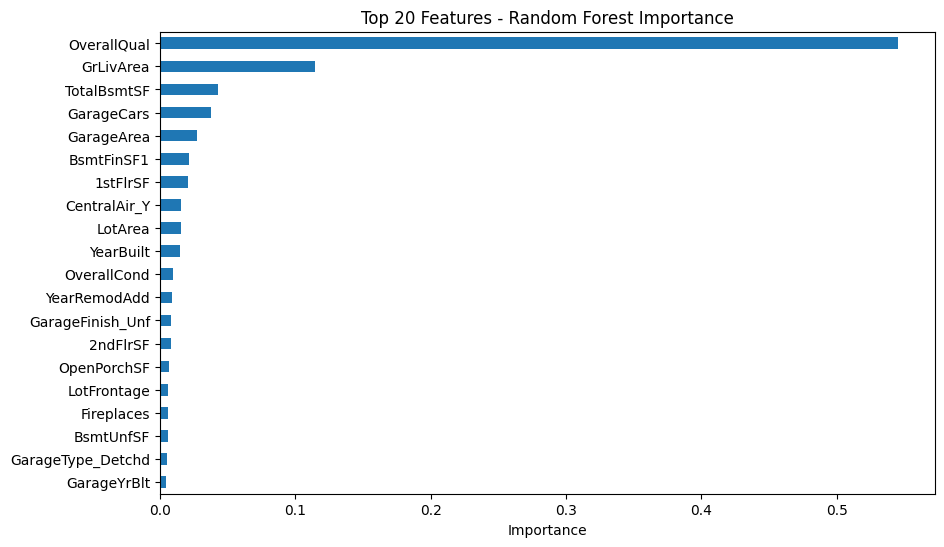

In [100]:
plt.figure(figsize=(10, 6))

rf_importance.head(20).sort_values().plot(
    kind="barh"
)

plt.title("Top 20 Features - Random Forest Importance")
plt.xlabel("Importance")
plt.show()

In [101]:
def select_rf_importance(X_train, X_test, y_train, k):
    selector_model = RandomForestRegressor(
        n_estimators=300,
        random_state=seed,
        n_jobs=-1
    )

    selector_model.fit(
        X_train,
        y_train
    )

    importance = pd.Series(
        selector_model.feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=False)

    selected_features = importance.head(k).index

    return (
        X_train[selected_features],
        X_test[selected_features],
        selected_features
    )

## 8. Các mô hình cơ bản

### SVM Regression (SVR)

SVR cần dữ liệu được chuẩn hóa.

In [102]:
def create_svm():
    return SVR(
        kernel="rbf",
        C=10,
        gamma="scale",
        epsilon=0.01
    )    

### Random Forest Regression

In [103]:
def create_random_forest():
    return RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        random_state=seed,
        n_jobs=-1
    )

### XGBoost Regression

In [104]:
def create_xgboost():
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=seed,
        n_jobs=-1
    )

## 9. Hàm đánh giá mô hình

In [105]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    return rmse

## 10. Thực nghiệm Feature Selection + SVM

In [106]:
results_svm = []

for method in ["F-test", "Mutual Information", "RF Importance"]:
    for k in feature_numbers:

        if method == "F-test":
            Xtr, Xte, selector = select_f_test(X_train_scaled, X_test_scaled, y_train, k)

        elif method == "Mutual Information":
            Xtr, Xte, selector = select_mutual_information(X_train_scaled, X_test_scaled, y_train, k)

        else:
            Xtr, Xte, selected_features = select_rf_importance(X_train_processed, X_test_processed, y_train, k)

        rmse = evaluate_model(create_svm(), Xtr, Xte, y_train, y_test)

        results_svm.append({"Feature Selection": method, "Features": k, "Model": "SVM", "RMSE": rmse})

results_svm = pd.DataFrame(results_svm)
display.display(results_svm)

,Feature Selection,Features,Model,RMSE
0,F-test,25,SVM,0.177163
1,F-test,50,SVM,0.161808
2,F-test,75,SVM,0.163753
3,F-test,100,SVM,0.211477
4,F-test,150,SVM,0.259570
5,F-test,200,SVM,0.371901
6,Mutual Information,25,SVM,0.159236
7,Mutual Information,50,SVM,0.152771
8,Mutual Information,75,SVM,0.145453
9,Mutual Information,100,SVM,0.152614


## 11. Thực nghiệm Feature Selection + Random Forest

In [107]:
results_rf = []

for method in ["F-test", "Mutual Information", "RF Importance"]:
    for k in feature_numbers:

        if method == "F-test":
            Xtr, Xte, selector = select_f_test(X_train_processed, X_test_processed, y_train, k)

        elif method == "Mutual Information":
            Xtr, Xte, selector = select_mutual_information(X_train_processed, X_test_processed, y_train, k)

        else:
            Xtr, Xte, selected_features = select_rf_importance(X_train_processed, X_test_processed, y_train, k)

        rmse = evaluate_model(create_random_forest(), Xtr, Xte, y_train, y_test)

        results_rf.append({"Feature Selection": method, "Features": k, "Model": "Random Forest", "RMSE": rmse})

results_rf = pd.DataFrame(results_rf)
display.display(results_rf)

,Feature Selection,Features,Model,RMSE
0,F-test,25,Random Forest,0.157242
1,F-test,50,Random Forest,0.153981
2,F-test,75,Random Forest,0.152186
3,F-test,100,Random Forest,0.152018
4,F-test,150,Random Forest,0.153097
5,F-test,200,Random Forest,0.148183
6,Mutual Information,25,Random Forest,0.157162
7,Mutual Information,50,Random Forest,0.148567
8,Mutual Information,75,Random Forest,0.147804
9,Mutual Information,100,Random Forest,0.148186


## 12. Thực nghiệm Feature Selection + XGBoost

In [108]:
results_xgb = []

for method in ["F-test", "Mutual Information", "RF Importance"]:
    for k in feature_numbers:

        if method == "F-test":
            Xtr, Xte, selector = select_f_test(X_train_processed, X_test_processed, y_train, k)

        elif method == "Mutual Information":
            Xtr, Xte, selector = select_mutual_information(X_train_processed, X_test_processed, y_train, k)

        else:
            Xtr, Xte, selected_features = select_rf_importance(X_train_processed, X_test_processed, y_train, k)

        rmse = evaluate_model(create_xgboost(), Xtr, Xte, y_train, y_test)

        results_xgb.append({"Feature Selection": method, "Features": k, "Model": "XGBoost", "RMSE": rmse})

results_xgb = pd.DataFrame(results_xgb)
display.display(results_xgb)

,Feature Selection,Features,Model,RMSE
0,F-test,25,XGBoost,0.152076
1,F-test,50,XGBoost,0.141947
2,F-test,75,XGBoost,0.143556
3,F-test,100,XGBoost,0.145897
4,F-test,150,XGBoost,0.139628
5,F-test,200,XGBoost,0.133641
6,Mutual Information,25,XGBoost,0.146396
7,Mutual Information,50,XGBoost,0.135505
8,Mutual Information,75,XGBoost,0.135467
9,Mutual Information,100,XGBoost,0.136435


## 13. Kết quả tốt nhất của từng mô hình

In [109]:
best_by_model = (
    results
    .sort_values("RMSE")
    .groupby("Model", as_index=False)
    .first()
    .sort_values("RMSE")
)

display.display(best_by_model)

,Model,Feature Selection,Features,RMSE
2,XGBoost,Mutual Information,150,0.130128
1,SVM,Mutual Information,75,0.144994
0,Random Forest,Mutual Information,100,0.147787


### Cấu hình tốt nhất toàn bộ thực nghiệm

In [110]:
best_result = results.iloc[0]

print("Feature Selection:", best_result["Feature Selection"])
print("Số Features:", best_result["Features"])
print("Model:", best_result["Model"])
print("RMSE:", best_result["RMSE"])

Feature Selection: Mutual Information
Số Features: 150
Model: XGBoost
RMSE: 0.13012820931834793


## 14. Biểu đồ so sánh

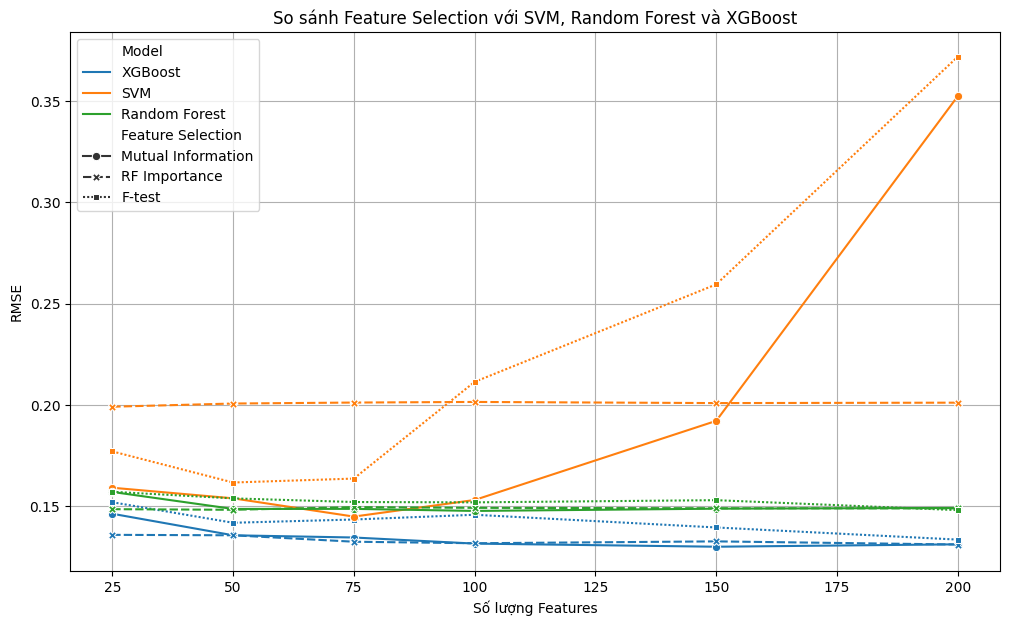

In [111]:
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=results,
    x="Features",
    y="RMSE",
    hue="Model",
    style="Feature Selection",
    markers=True
)

plt.title("So sánh Feature Selection với SVM, Random Forest và XGBoost")
plt.xlabel("Số lượng Features")
plt.ylabel("RMSE")
plt.grid(True)
plt.show()

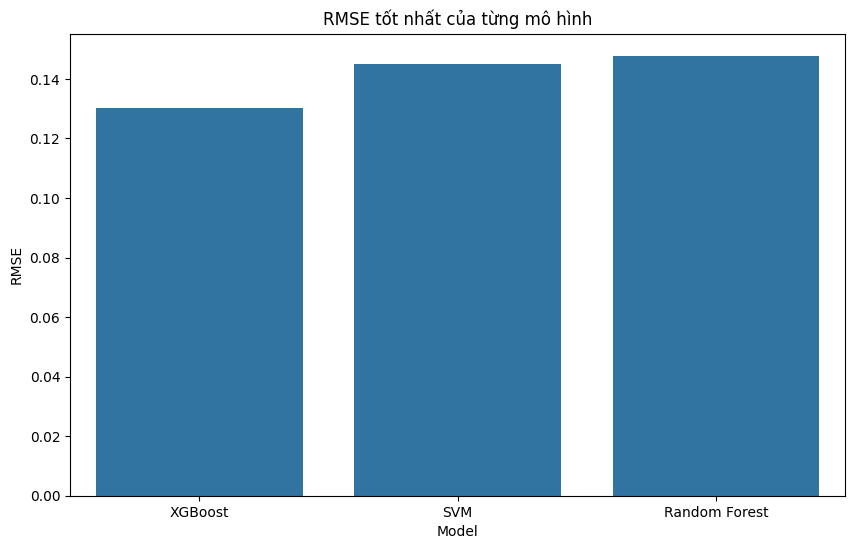

In [112]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=best_by_model,
    x="Model",
    y="RMSE"
)

plt.title("RMSE tốt nhất của từng mô hình")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.show()

# Kết thúc